# 3. 공간 필터링 (Spatial Filtering)

한 픽셀을 바꿀 때 **주변 픽셀을 함께 살펴보는 방법**이다. 이웃 값을 평균내거나, 중앙값을 고르거나, 최솟값·최댓값을 선택하여 흐림·잡음 감소·경계 강조·형태 변화를 만든다.

| 분류 | 대표 연산 | 계산 방식 |
| :---: | :---: | :---: |
| 선형 필터 | 평균, 가우시안, Sobel, 라플라시안 | 고정 가중치의 합 |
| 비선형 필터 | 미디언, 양방향, 형태학 | 중앙값, 입력 의존 가중치, 최솟값·최댓값 |

형태학은 비선형 공간 처리에 속하며, 3.4에서 별도로 자세히 다룬다.

### 입력 영상과 표시 함수

- 레나는 제공된 원본을 그레이스케일로 바꿔 사용한다.
- 미분과 차분 결과는 음수가 나올 수 있어 `float32`로 계산한다.
- 일반 영상은 0~255, 부호 있는 영상은 양수·음수를 구분하는 색상과 색 막대로 표시한다.

OpenCV: 5.0.0 영상 크기: (250, 250)


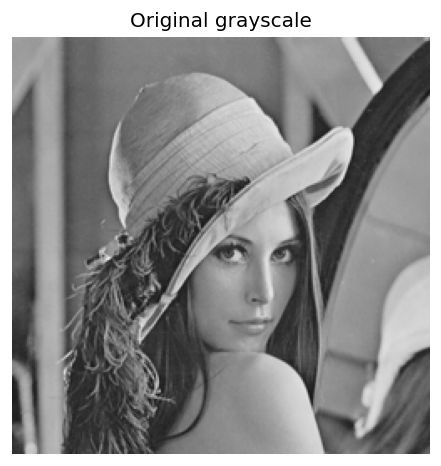

In [1]:
# 셀 1: 실습 영상과 출력 함수
# 그레이스케일을 float32로 바꾸어 미분과 차분의 음수를 보존한다.

# Path는 운영체제에 맞게 파일 경로를 조합하는 데 사용한다.
from pathlib import Path
import json
# OpenCV는 영상 처리, NumPy는 배열 계산, Matplotlib은 결과 시각화에 사용한다.
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 현재 작업 폴더를 기준으로 assets를 찾는다. 노트북은 각 장의 폴더에서 실행한다.
ROOT = Path.cwd()  # 노트북과 assets 폴더가 있는 위치
OUT = ROOT / 'assets'
# 파일을 바이트 배열로 읽어 디코딩한다. IMREAD_COLOR의 결과는 BGR 순서다.
img = cv2.imdecode(np.fromfile(OUT/'Lenna.png', np.uint8), cv2.IMREAD_COLOR)
if img is None:
    raise FileNotFoundError('assets/Lenna.png를 확인하세요.')
# B·G·R을 밝기 가중합으로 바꾸어 단일 채널 영상으로 만든다.
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
f = gray.astype(np.float32)
border = cv2.BORDER_REFLECT_101

# 비교 그림의 배치를 통일하고, 영상 또는 결과 배열을 화면에 표시한다.
def panel(name, items, cols=3, signed=False):
    fig, axes = plt.subplots((len(items)+cols-1)//cols, cols, figsize=(4*cols,4*((len(items)+cols-1)//cols)), squeeze=False)
    for ax, (title, a) in zip(axes.flat, items):
        if signed:
            m = max(float(np.abs(a).max()), 1e-6)
            im = ax.imshow(a, cmap='coolwarm', vmin=-m, vmax=m)
            fig.colorbar(im, ax=ax, shrink=.65)
        else:
            ax.imshow(a, cmap='gray', vmin=0, vmax=255)
        ax.set_title(title); ax.axis('off')
    for ax in list(axes.flat)[len(items):]: ax.axis('off')
    fig.tight_layout(); plt.show()


print('OpenCV:',cv2.__version__,'영상 크기:',gray.shape)
panel('original.png',[('Original grayscale',gray)],cols=1)

## 3.1 마스크 기반 처리의 원리

### 이웃 영역과 커널

- 픽셀 주변에 작은 창을 올리고 한 칸씩 이동한다고 생각한다.
- 선형 필터의 커널은 각 위치에 적용할 **가중치 표**다.
- 미디언은 주변 값의 중앙값을 고르며, 형태학은 구조 요소로 선택한 영역의 최솟값·최댓값 등을 사용한다.
- 따라서 작은 창을 사용한다고 모두 합성곱인 것은 아니다.
- 아래에서는 홀수 크기 커널의 중심을 기준점(anchor)으로 사용한다.

주변 값이 다음과 같고 모든 가중치가 $1/9$라면 가운데 출력은 5다.

$$
P=\begin{bmatrix}1&2&3\\4&5&6\\7&8&9\end{bmatrix},\qquad
K=\frac{1}{9}\begin{bmatrix}1&1&1\\1&1&1\\1&1&1\end{bmatrix}
$$

$$
g=\frac{1+2+3+4+5+6+7+8+9}{9}=5
$$

실제 연산은 출력 배열에 기록한다. 입력을 제자리에서 순서대로 덮어쓰는 손계산과 혼동하지 않는다.

### 합성곱과 상관 연산

입력 $f[y,x]$, 중심 기준 커널 $K[j,i]$에 대해:

$$
\text{상관: }g[y,x]=\sum_j\sum_i K[j,i]f[y+j,x+i]
$$

$$
\text{합성곱: }g[y,x]=\sum_j\sum_i K[j,i]f[y-j,x-i]
$$

- 상관은 커널을 그대로 사용한다.
- 합성곱은 커널을 가로·세로로 뒤집어 적용하는 것과 같다.
- 평균·가우시안처럼 중심 대칭인 커널은 두 결과가 같다.
- 비대칭 커널은 다를 수 있다. 위 행렬에서 오른쪽 이웃만 고르면 상관 결과는 6, 뒤집어 왼쪽을 고르면 합성곱 결과는 4다.



> [!warning] 적용 범위
> 위 뒤집기 예제는 홀수 크기·중앙 anchor 기준이다. 다른 anchor를 사용한다면 뒤집은 커널에 맞게 anchor도 조정해야 한다.

In [2]:
# 셀 2: 상관과 합성곱의 차이
# 중심 기준 비대칭 커널로 오른쪽 값 6과 왼쪽 값 4가 선택되는지 확인한다.

a = np.arange(1,10,dtype=np.float32).reshape(3,3)
k_mean = np.ones((3,3),np.float32)/9
# 오른쪽 이웃 하나만 선택하는 비대칭 커널로 뒤집기의 효과를 확인한다.
k_asym = np.array([[0,0,0],[0,0,1],[0,0,0]],np.float32)
# filter2D는 커널을 뒤집지 않는 상관 연산을 수행한다.
corr = cv2.filter2D(a,-1,k_asym,borderType=border)
# 중앙 anchor의 홀수 커널을 양축으로 뒤집어 합성곱 결과를 구한다.
conv = cv2.filter2D(a,-1,cv2.flip(k_asym,-1),borderType=border)
print('입력:\n',a)
print('평균 필터의 중심:',cv2.filter2D(a,-1,k_mean)[1,1])
print('상관 중심:',corr[1,1], '합성곱 중심:',conv[1,1])
assert corr[1,1] == 6 and conv[1,1] == 4

입력:
 [[1. 2. 3.]
 [4. 5. 6.]
 [7. 8. 9.]]
평균 필터의 중심: 5.0
상관 중심: 6.0 합성곱 중심: 4.0


### 경계 처리

영상 가장자리에서는 커널 일부가 영상 밖으로 나간다. 바깥 값을 어떻게 정할지 선택해야 한다.

| 방법 | 바깥 값 설정 | 주의점 |
| :---: | :---: | :---: |
| `BORDER_CONSTANT` | 지정한 상수 | 0을 쓰면 밝은 영상 가장자리가 어두워질 수 있음 |
| `BORDER_REPLICATE` | 가장자리 값 반복 | 끝 값이 이어짐 |
| `BORDER_REFLECT` | 가장자리 값까지 포함해 반사 | 끝 픽셀이 중복됨 |
| `BORDER_REFLECT_101` | 끝 픽셀을 중복하지 않고 반사 | 일반적인 선형 필터 비교에 사용 |

예를 들어 한 줄의 왼쪽 끝 값이 `[10, 20, 30]`이면 왼쪽 바로 바깥 값은 REPLICATE와 REFLECT에서는 10, REFLECT_101에서는 20이다.

실습의 주요 선형 필터는 `BORDER_REFLECT_101`을 사용한다. 미디언은 OpenCV에서 REPLICATE 경계를 사용하므로 잡음 비교 패널의 가우시안·양방향도 REPLICATE로 맞췄다. 형태학 역시 REPLICATE로 명시했다.

CONSTANT [0.0, 10.0, 20.0, 30.0, 0.0]
REPLICATE [10.0, 10.0, 20.0, 30.0, 30.0]
REFLECT [10.0, 10.0, 20.0, 30.0, 30.0]
REFLECT_101 [20.0, 10.0, 20.0, 30.0, 20.0]
Zero border 왼쪽 위: 72.0
Replicate 왼쪽 위: 200.0
Reflect 101 왼쪽 위: 200.0


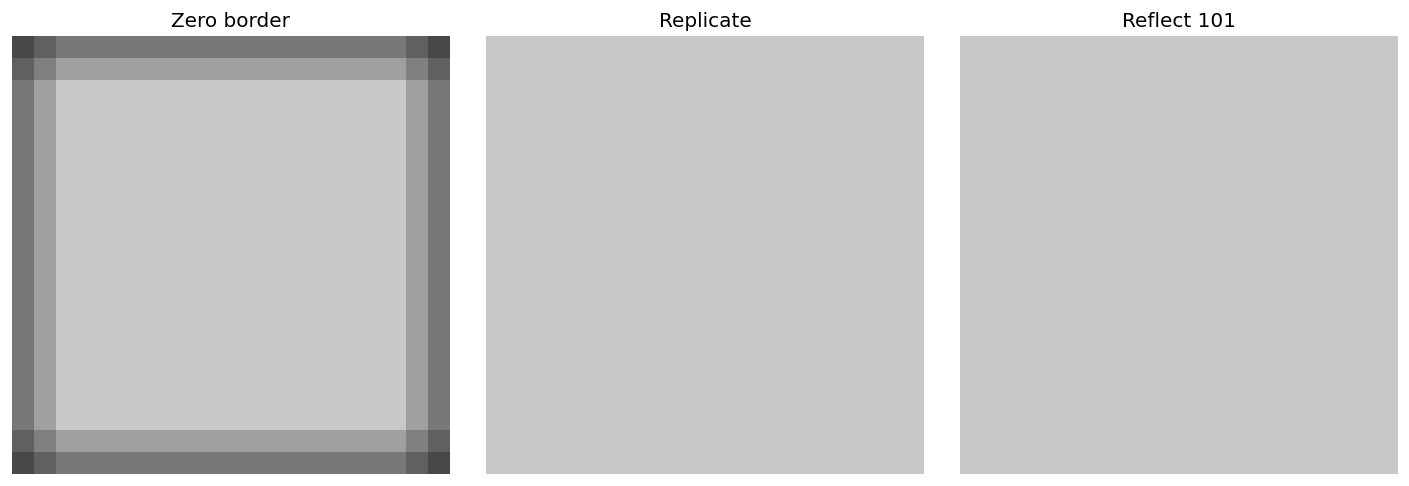

In [3]:
# 셀 3: 경계 밖 값의 처리
# 같은 입력이라도 0 채우기·반복·반사 방식에 따라 가장자리 계산이 달라진다.

line = np.array([[10,20,30]],np.float32)
for name,mode in [('CONSTANT',cv2.BORDER_CONSTANT),('REPLICATE',cv2.BORDER_REPLICATE),
                  ('REFLECT',cv2.BORDER_REFLECT),('REFLECT_101',cv2.BORDER_REFLECT_101)]:
    print(name,cv2.copyMakeBorder(line,0,0,1,1,mode,value=0).ravel().tolist())
bright_test = np.full((20,20),200,np.float32)
items=[]
for name,mode in [('Zero border',cv2.BORDER_CONSTANT),('Replicate',cv2.BORDER_REPLICATE),
                  ('Reflect 101',cv2.BORDER_REFLECT_101)]:
    result=cv2.blur(bright_test,(5,5),borderType=mode)
    items.append((name,result))
    print(name,'왼쪽 위:',result[0,0])
panel('border.png',items)

## 3.2 선형 공간 필터

### 선형의 뜻

고정된 계수의 필터 $F$가 다음 성질을 만족하면 선형이다.

$$
F(af+bg)=aF(f)+bF(g)
$$

입력을 섞은 뒤 처리한 결과와, 각각 처리한 뒤 같은 비율로 섞은 결과가 같다. 정수 반올림·클리핑은 이 성질을 깨뜨릴 수 있으므로 여기서는 필터의 실수 연산 자체를 분류한다.

### 평균 필터

- 이웃 픽셀을 같은 비중으로 평균낸다.
- 작은 변화가 줄어들지만 경계도 흐려질 수 있다.
- 커널이 커지면 더 넓은 영역이 섞인다.



### 가우시안 필터

- 가까운 픽셀에 더 큰 가중치를 주는 종 모양 커널이다.
- 아래 연속 함수에서 값을 샘플링하고 커널 합이 1이 되도록 정규화한다.
- $\sigma$는 퍼짐 정도다. 커널 크기도 충분히 커야 의도한 퍼짐을 표현한다.

$$
G_\sigma(x,y)=\frac{1}{2\pi\sigma^2}\exp\left(-\frac{x^2+y^2}{2\sigma^2}\right)
$$

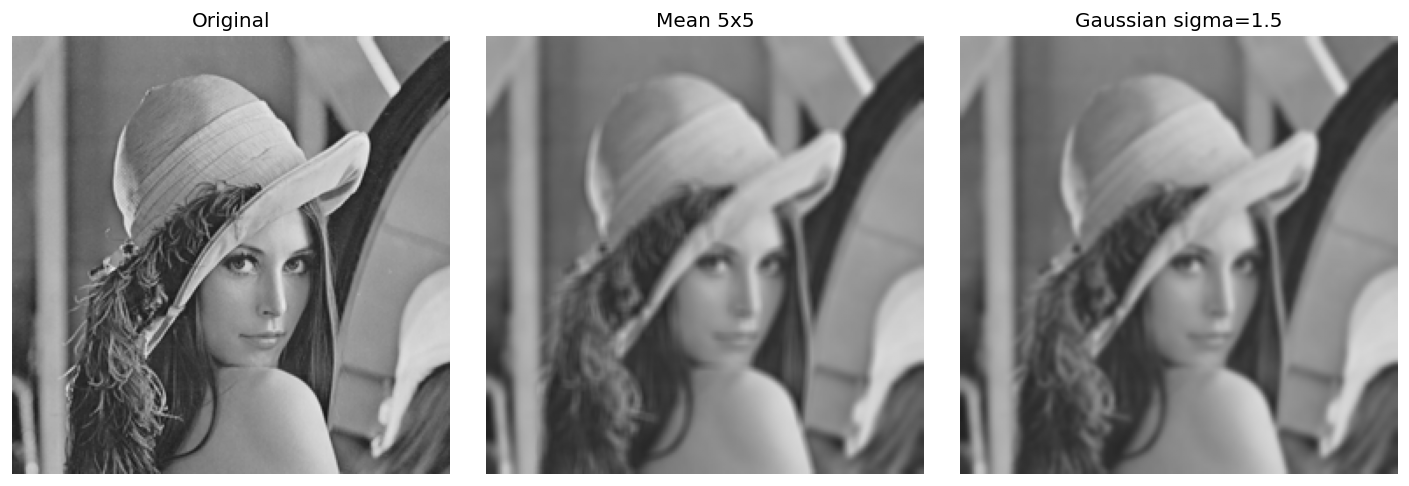

In [4]:
# 셀 4: 평균 및 가우시안 필터
# 같은 비중의 평균과 중심에 큰 비중을 주는 가우시안의 흐림 효과를 비교한다.

# 5×5 이웃을 같은 비중으로 평균내며 반사 경계 처리를 사용한다.
avg = cv2.blur(f,(5,5),borderType=border)
# 9×9 커널과 sigma=1.5를 사용하여 가까운 이웃에 더 큰 가중치를 준다.
gauss = cv2.GaussianBlur(f,(9,9),1.5,borderType=border)
panel('smoothing.png',[('Original',f),('Mean 5x5',avg),('Gaussian sigma=1.5',gauss)])

### Sobel과 라플라시안

| 방법 | 살펴보는 것 | 해석 |
| :---: | :---: | :---: |
| Sobel x | 가로 방향 밝기 변화 | 세로 경계에 강하게 반응할 수 있음 |
| Sobel y | 세로 방향 밝기 변화 | 가로 경계에 강하게 반응할 수 있음 |
| 라플라시안 | 두 방향의 2차 변화 합 | 경계·미세 변화 및 잡음에도 민감 |

$$
K_x=\begin{bmatrix}-1&0&1\\-2&0&2\\-1&0&1\end{bmatrix},\quad
K_y=\begin{bmatrix}-1&-2&-1\\0&0&0\\1&2&1\end{bmatrix}
$$

$$
\nabla^2 f=\frac{\partial^2 f}{\partial x^2}+\frac{\partial^2 f}{\partial y^2},\qquad
K_L=\begin{bmatrix}0&1&0\\1&-4&1\\0&1&0\end{bmatrix}
$$





- 이 그림은 부호를 보존해 파랑·빨강으로 표시했다. 각 패널의 색 범위는 독립적이다.
- `uint8` 출력만 쓰면 음수 변화가 잘려서 사라질 수 있다.
- Sobel 결과 $s_x,s_y$는 선형이지만 $\sqrt{s_x^2+s_y^2}$로 합친 크기 연산은 비선형이다.
- 위 라플라시안 커널은 `ksize=1`에 해당한다. 다른 크기에는 그대로 적용되지 않는다.

Sobel x 범위: -801.0 610.0
Laplacian 범위: -326.0 302.0


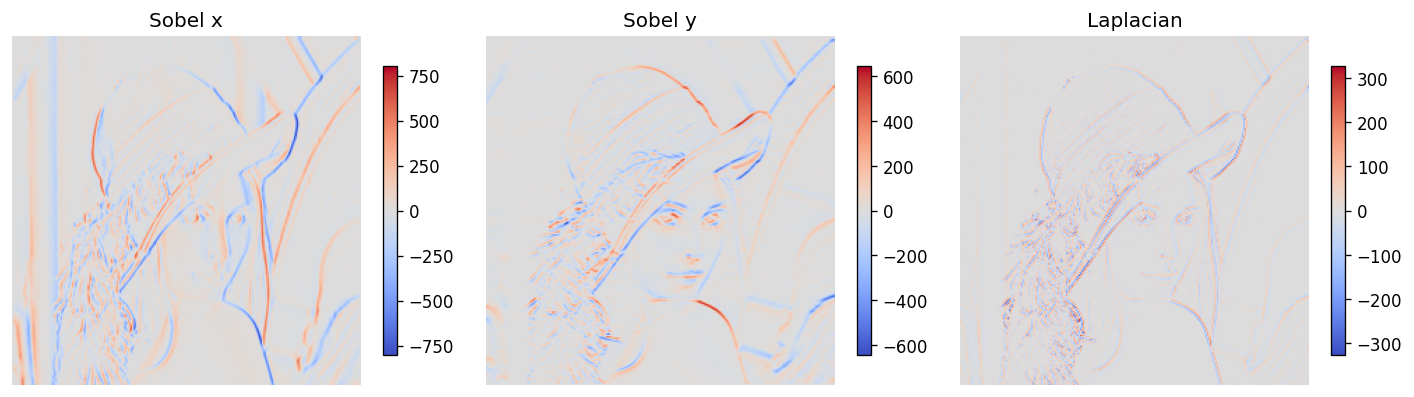

In [5]:
# 셀 5: Sobel과 라플라시안
# Sobel은 방향별 1차 변화, 라플라시안은 2차 변화를 나타낸다. 결과의 부호를 유지한다.

# dx=1, dy=0은 가로 방향 미분이며 세로 경계에 강하게 반응한다.
sx = cv2.Sobel(f,cv2.CV_32F,1,0,ksize=3,borderType=border)
# dx=0, dy=1은 세로 방향 미분이며 가로 경계에 강하게 반응한다.
sy = cv2.Sobel(f,cv2.CV_32F,0,1,ksize=3,borderType=border)
# ksize=1의 라플라시안으로 2차 변화를 계산하고 CV_32F로 음수를 보존한다.
lap = cv2.Laplacian(f,cv2.CV_32F,ksize=1,borderType=border)

panel('derivatives.png',[('Sobel x',sx),('Sobel y',sy),('Laplacian',lap)],signed=True)
print('Sobel x 범위:',float(sx.min()),float(sx.max()))
print('Laplacian 범위:',float(lap.min()),float(lap.max()))

### 샤프닝

흐린 영상과 원본의 차이를 더하는 언샤프 마스킹:

$$
g=f+\alpha(f-G_\sigma*f),\qquad \alpha>0
$$

위 부호의 라플라시안 커널을 사용하는 샤프닝:

$$
g=f-\lambda\nabla^2f,\qquad \lambda>0
$$





원본과 같은 0~255 표시 범위를 사용했다. 과도한 샤프닝은 테두리의 밝고 어두운 띠나 잡음을 강조할 수 있다. 고정 계수의 조합은 클리핑 전에는 선형이며, 표시용 클리핑은 별도 단계다.

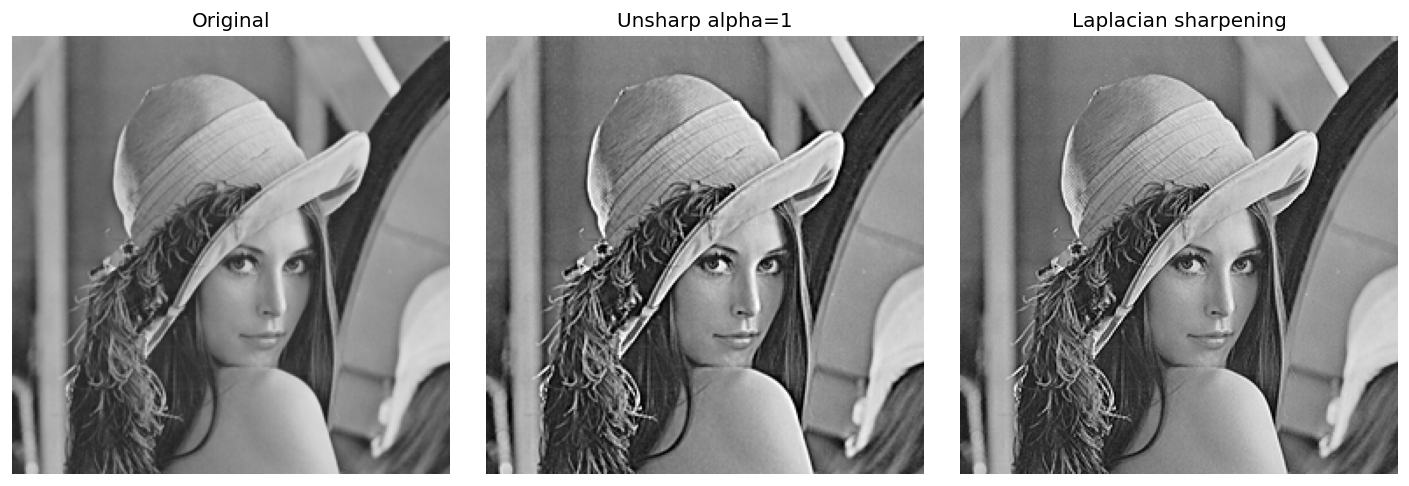

In [6]:
# 셀 6: 샤프닝
# 원본에 미세 변화를 더해 경계를 강조하고, 표시할 때만 0~255로 제한한다.

# 원본에서 흐림 결과를 뺀 고주파 성분을 원본에 더한다.
sharp = np.clip(f + (f-gauss),0,255)
# 중앙 계수가 음수인 라플라시안 결과를 빼서 경계를 강조한다.
sharp_lap = np.clip(f-0.25*lap,0,255)
panel('sharpen.png',[('Original',f),('Unsharp alpha=1',sharp),('Laplacian sharpening',sharp_lap)])

## 3.3 비선형 공간 필터

### 미디언 필터

- 주변 값을 정렬한 뒤 중앙값을 고른다.
- 평균과 달리 매우 큰 값 하나에 크게 끌려가지 않는다.
- 예를 들어 `[10, 10, 10, 10, 255]`의 평균은 59지만 중앙값은 10이다.
- 소금·후추처럼 드문 흰 점·검은 점 잡음에 유용할 수 있다.
- 작은 선이나 세부 무늬도 없어질 수 있다.

$$
g[y,x]=\operatorname{median}\{f[y+j,x+i]:(j,i)\in\mathcal N\}
$$



### 양방향 필터

- 가까우면서 픽셀 값도 비슷한 이웃에 큰 가중치를 준다.
- 경계를 가로질러 크게 다른 값을 덜 섞어 경계 보존을 돕는다.
- 가중치가 입력 값에 따라 달라지므로 비선형이다.

$$
g(p)=\frac{\sum_{q\in\mathcal N(p)}w(p,q)f(q)}{\sum_{q\in\mathcal N(p)}w(p,q)}
$$

$$
w(p,q)=\exp\left(-\frac{\|p-q\|^2}{2\sigma_s^2}\right)
\exp\left(-\frac{(f(p)-f(q))^2}{2\sigma_r^2}\right)
$$



| 인수 | 의미 |
| :---: | :---: |
| d | 이웃 영역의 지름 |
| sigmaColor | 허용하는 값 차이의 규모 |
| sigmaSpace | 거리 가중치의 규모 |



잡음은 원본과 별도로 확률 0.05, 난수 시드 42로 생성했다. 가우시안·미디언·양방향 모두 같은 잡음 입력을 받는다. 양방향 필터는 값 차이가 큰 점 잡음을 이웃과 섞지 않아 남길 수 있다. 이 예제 하나로 모든 잡음에 대한 성능 순위를 정하지 않는다.



두 필터의 강도가 동등하게 보정된 비교는 아니다. 모자와 얼굴 경계, 평탄한 영역을 중심으로 동작 차이를 관찰한다.

Noisy 원본 대비 MAE: 6.397
Gaussian 원본 대비 MAE: 8.53
Median 원본 대비 MAE: 4.994
Bilateral 원본 대비 MAE: 9.278


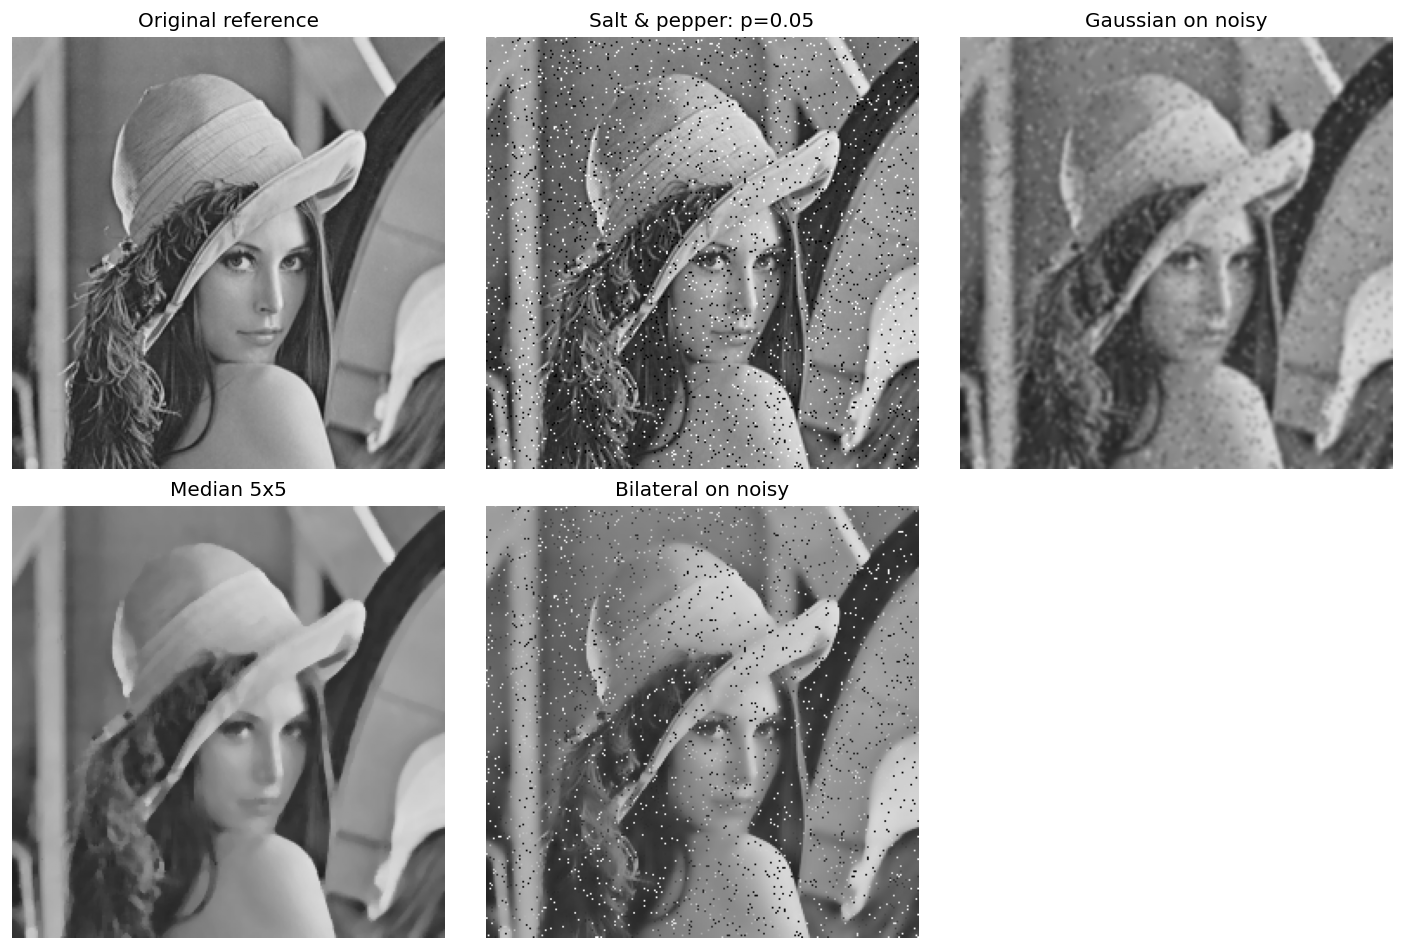

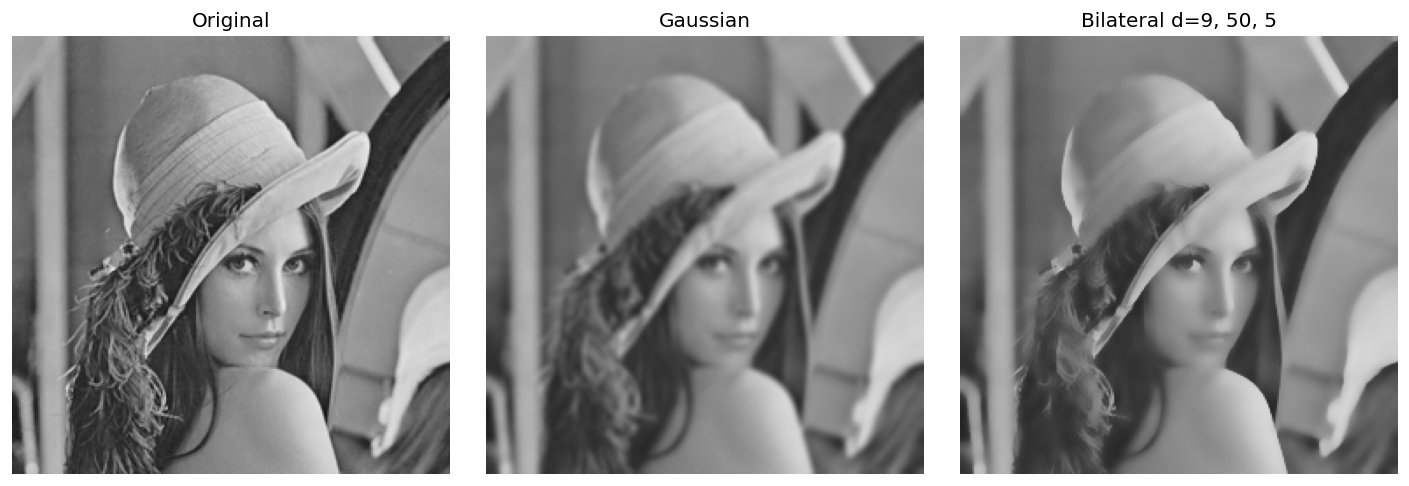

In [7]:
# 셀 7: 비선형 필터와 잡음
# 동일한 소금·후추 잡음 입력에 가우시안·미디언·양방향 필터를 적용한다.

# 같은 잡음 입력으로 비교하며 난수 시드를 고정합니다.
rng = np.random.default_rng(42)
noisy = gray.copy(); u = rng.random(gray.shape)
noisy[u<.025]=0; noisy[u>.975]=255
# 5×5 이웃의 중앙값을 고른다. 드문 흰 점·검은 점에 덜 끌리는 특성이 있다.
med = cv2.medianBlur(noisy,5)
# 지름 9의 이웃에서 밝기 차이 규모 50, 거리 규모 5로 가중치를 조절한다.
bil = cv2.bilateralFilter(noisy,9,50,5,borderType=cv2.BORDER_REPLICATE)
ng = cv2.GaussianBlur(noisy,(5,5),1.2,borderType=cv2.BORDER_REPLICATE)
panel('nonlinear.png',[('Original reference',gray),('Salt & pepper: p=0.05',noisy),('Gaussian on noisy',ng),('Median 5x5',med),('Bilateral on noisy',bil)])
# 지름 9의 이웃에서 밝기 차이 규모 50, 거리 규모 5로 가중치를 조절한다.
bil_clean = cv2.bilateralFilter(gray,9,50,5,borderType=border)
panel('bilateral.png',[('Original',gray),('Gaussian',gauss),('Bilateral d=9, 50, 5',bil_clean)])


for name,a in [('Noisy',noisy),('Gaussian',ng),('Median',med),('Bilateral',bil)]:
    print(name,'원본 대비 MAE:',round(float(np.abs(a.astype(np.float32)-f).mean()),3))

### 잡음 비교의 해석

- 같은 잡음 영상과 같은 경계 처리 조건을 사용했다. 필터의 강도가 완전히 동등한 비교는 아니다.
- MAE는 원본과의 픽셀 값 차이의 평균이다. 이 합성 잡음 실험의 복원 오차이며, 모든 사진의 품질을 나타내는 점수는 아니다.
- 미디언은 드문 극단값을 줄이는 데 유리하지만, 작은 유효 구조도 없앨 수 있다.
- 실제 MAE는 잡음 입력 6.397, 가우시안 8.530, 미디언 4.994, 양방향 9.278이었다. 이 설정에서는 미디언만 원본 대비 평균 오차를 줄였다. 가우시안과 양방향 결과는 세부 변화 또는 잔여 잡음 때문에 오차가 더 컸다.

## 3.4 형태학적 처리 (Morphology)

### 구조 요소로 모양 살펴보기

- 비선형 공간 처리의 한 종류다. 이 절은 분량 때문에 따로 펼쳤다.
- 구조 요소는 어떤 이웃 위치를 사용할지 표시한 작은 모양이다.
- 평균 가중치가 아니라, 선택된 위치에서 최솟값·최댓값 등을 구한다.
- 이진 영상과 그레이스케일 영상 모두에 적용할 수 있다.



RECT는 사각형, CROSS는 십자, ELLIPSE는 타원 형태다. 크기와 모양에 따라 남거나 사라지는 구조가 달라진다.

### 침식과 팽창

아래는 중심 대칭·평탄 구조 요소 $B$를 사용하는 경우다.

$$
\operatorname{erode}(f)(p)=\min_{q\in B} f(p+q),\qquad
\operatorname{dilate}(f)(p)=\max_{q\in B} f(p+q)
$$

- 흰색 전경의 침식: 흰 영역을 줄인다.
- 흰색 전경의 팽창: 흰 영역을 늘린다.
- 검은 물체를 전경으로 해석하면 위 시각적 설명이 뒤바뀐다. 먼저 전경의 색을 정한다.

흰 픽셀 수: 10976 8927 12985


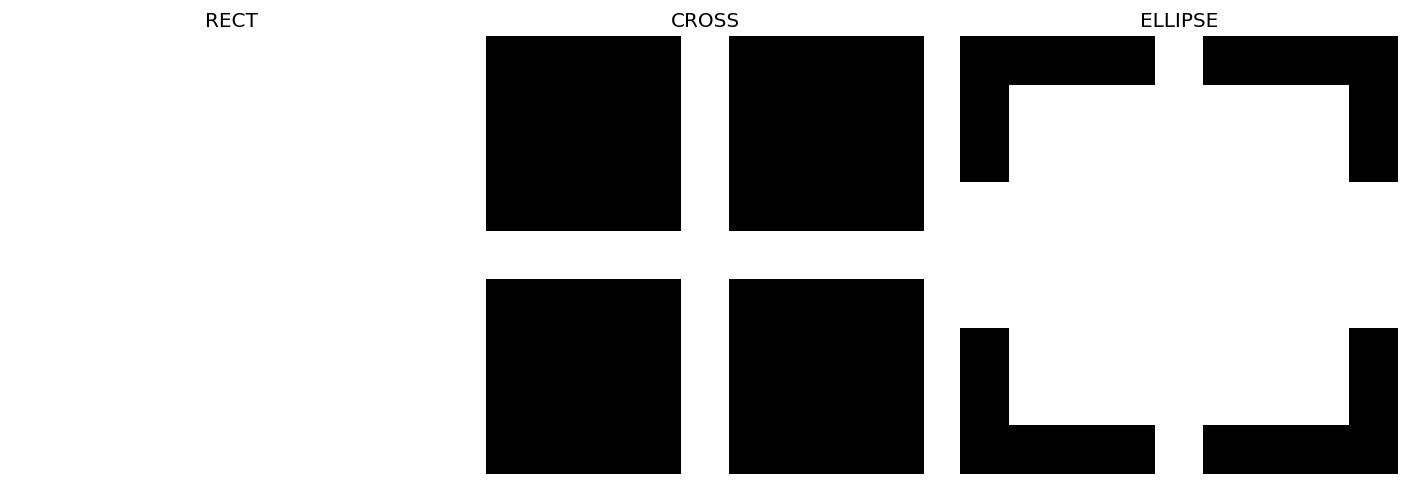

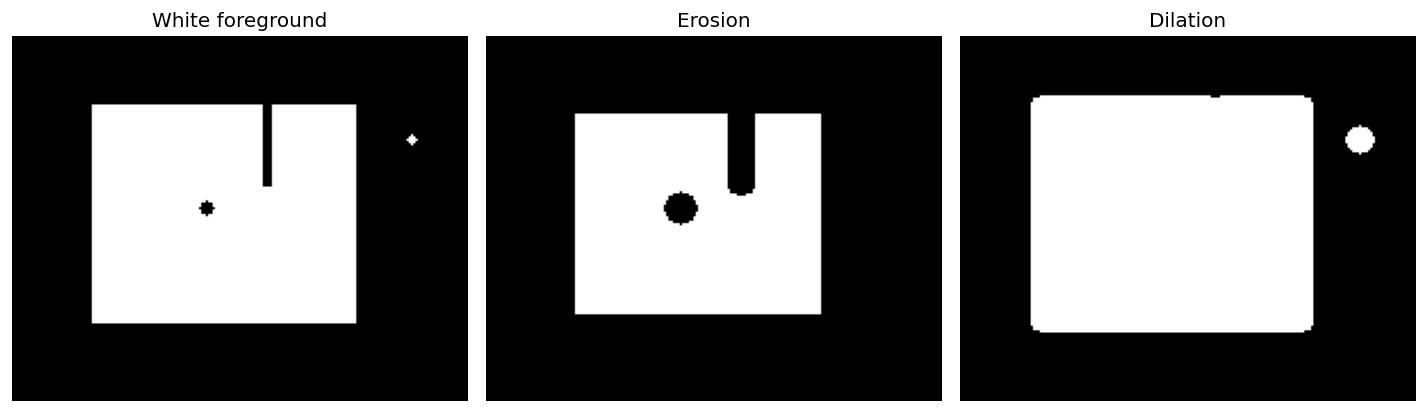

In [8]:
# 셀 8: 구조 요소, 침식, 팽창
# 흰색을 전경으로 정하고 구조 요소가 선택한 이웃의 최솟값·최댓값을 계산한다.

shapes = [('RECT',cv2.MORPH_RECT),('CROSS',cv2.MORPH_CROSS),('ELLIPSE',cv2.MORPH_ELLIPSE)]
panel('elements.png',[(name,cv2.getStructuringElement(shape,(9,9))*255) for name,shape in shapes])
binary=np.zeros((160,200),np.uint8)
# 오른쪽 아래 좌표도 포함해 그린다. 폭·높이에서 1을 빼면 지정한 픽셀 범위와 맞는다.
cv2.rectangle(binary,(35,30),(150,125),255,-1)
cv2.circle(binary,(85,75),3,0,-1)
# 오른쪽 아래 좌표도 포함해 그린다. 폭·높이에서 1을 빼면 지정한 픽셀 범위와 맞는다.
cv2.rectangle(binary,(110,30),(113,65),0,-1)
cv2.circle(binary,(175,45),2,255,-1)
# 9×9 타원 구조 요소에서 0이 아닌 위치를 형태학 연산의 이웃으로 사용한다.
k=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(9,9))
def morph(a,op):
    return cv2.morphologyEx(a,op,k,borderType=cv2.BORDER_REPLICATE)
# 이웃의 최솟값을 선택하여 흰색 전경을 줄인다.
er=cv2.erode(binary,k,borderType=cv2.BORDER_REPLICATE)
# 이웃의 최댓값을 선택하여 흰색 전경을 넓힌다.
di=cv2.dilate(binary,k,borderType=cv2.BORDER_REPLICATE)
panel('erode_dilate.png',[('White foreground',binary),('Erosion',er),('Dilation',di)])
assert np.all(er<=binary) and np.all(di>=binary)
print('흰 픽셀 수:',*[int(np.count_nonzero(a)) for a in [binary,er,di]])

### 열림·닫힘과 차이 연산

$$
\operatorname{open}(f)=\operatorname{dilate}(\operatorname{erode}(f))
$$

$$
\operatorname{close}(f)=\operatorname{erode}(\operatorname{dilate}(f))
$$

| 연산 | 계산 | 흰색 전경 또는 Gray에서의 관찰 |
| :---: | :---: | :---: |
| 열림 | 침식 → 팽창 | 작은 밝은 점·돌출부 등을 제거할 수 있음 |
| 닫힘 | 팽창 → 침식 | 작은 어두운 구멍·틈 등을 메울 수 있음 |
| 그래디언트 | 팽창 − 침식 | 영역 경계나 국소 밝기 변화 강조 |
| 탑햇 | 원본 − 열림 | 구조 요소보다 작은 밝은 구조 강조 |
| 블랙햇 | 닫힘 − 원본 | 구조 요소보다 작은 어두운 구조 강조 |

열림과 닫힘은 서로 역연산이 아니다. 제거된 모양이 반드시 복구되는 것도 아니다. 효과는 구조 요소에 대한 크기·모양 관계에 달려 있다.





도형은 원리를 보여주려고 별도로 만든 흰색 전경이다. 작은 흰 점, 내부의 검은 구멍, 위에서 내려오는 가느다란 틈을 비교한다.



레나에는 이진화하지 않고 Gray 그대로 적용했다. 탑햇과 블랙햇은 밝은·어두운 국소 세부에 반응하며, 사람이나 물체를 의미적으로 인식한 결과가 아니다.

작은 흰 점 제거: True
작은 검은 구멍 채움: True


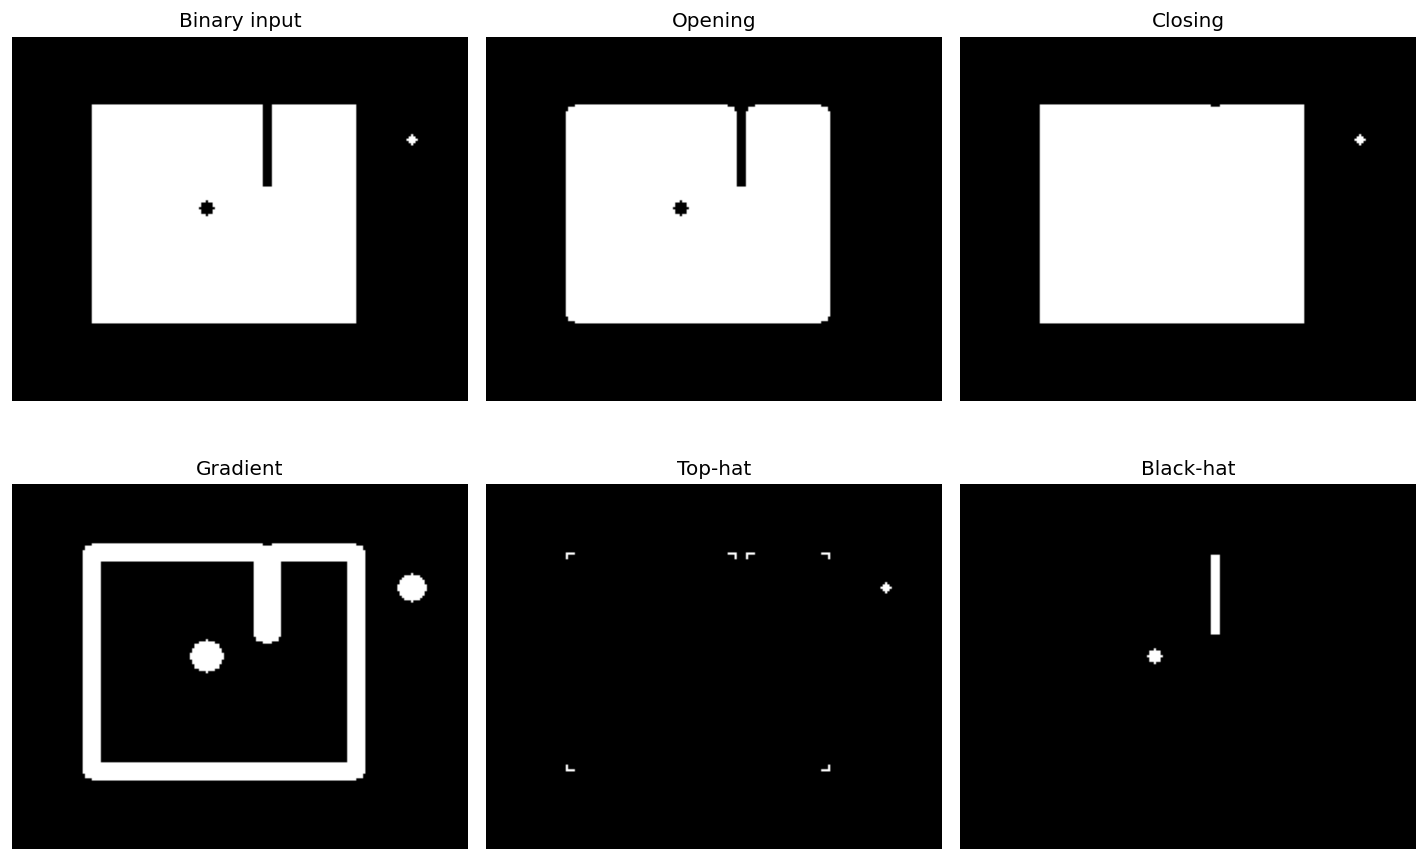

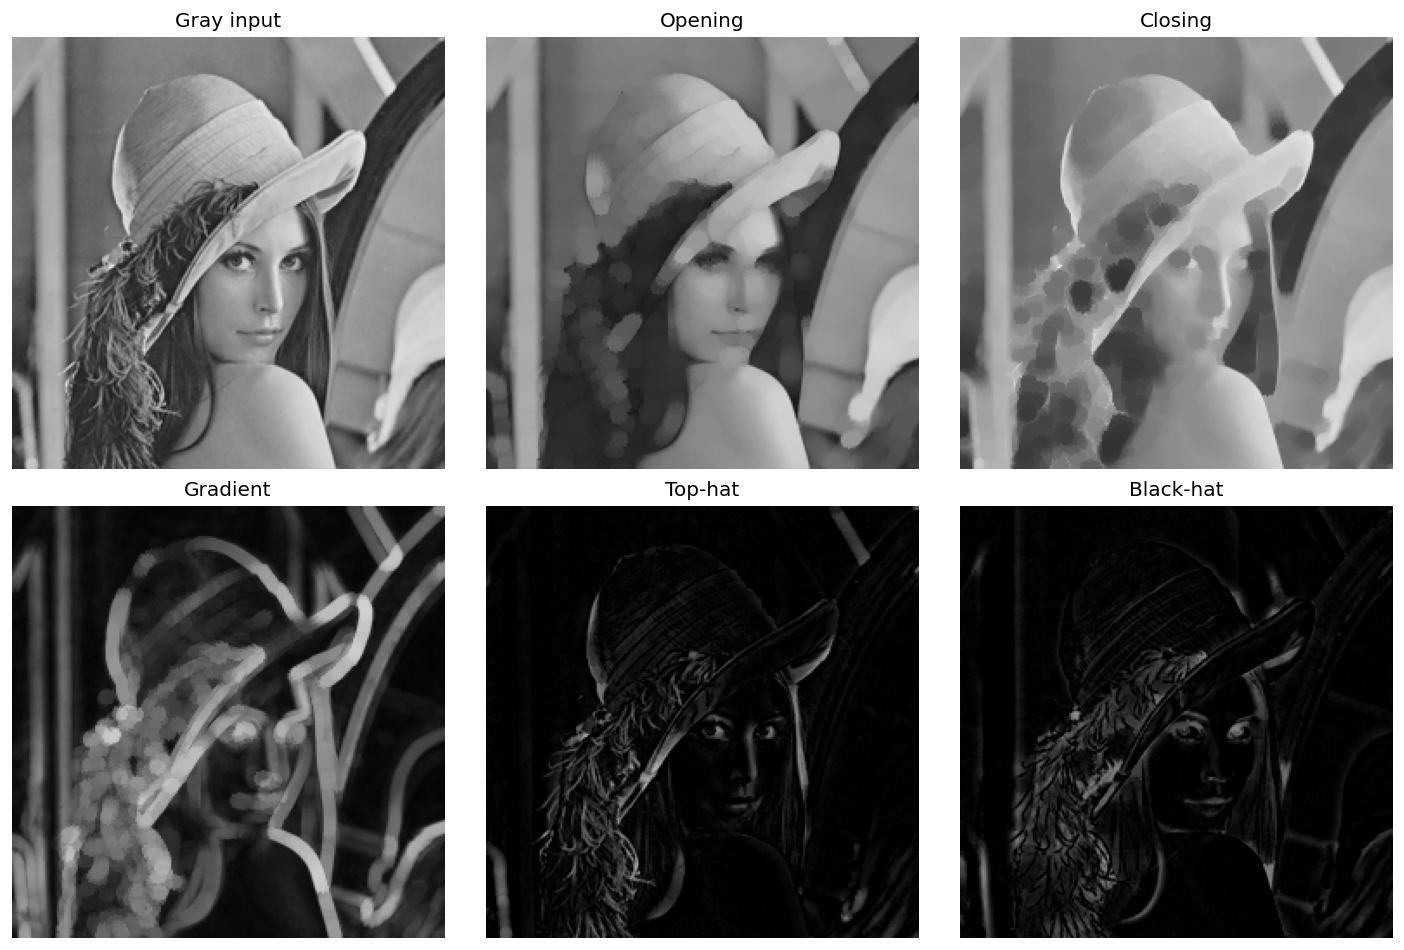

In [9]:
# 셀 9: 열림·닫힘과 형태학적 차이 연산
# 이진 도형과 그레이스케일에서 작은 구조 및 경계에 대한 반응을 비교한다.

ops=[('Opening',cv2.MORPH_OPEN),('Closing',cv2.MORPH_CLOSE),
     ('Gradient',cv2.MORPH_GRADIENT),('Top-hat',cv2.MORPH_TOPHAT),('Black-hat',cv2.MORPH_BLACKHAT)]
panel('binary.png',[('Binary input',binary)]+[(name,morph(binary,op)) for name,op in ops])
panel('gray.png',[('Gray input',gray)]+[(name,morph(gray,op)) for name,op in ops])
# 침식 다음 팽창을 적용하여 구조 요소보다 작은 밝은 구조를 줄인다.
opened=morph(binary,cv2.MORPH_OPEN)
# 팽창 다음 침식을 적용하여 작은 어두운 구멍이나 틈을 메운다.
closed=morph(binary,cv2.MORPH_CLOSE)
assert np.all(opened<=binary) and np.all(closed>=binary)
assert np.array_equal(morph(binary,cv2.MORPH_GRADIENT),cv2.subtract(di,er))
print('작은 흰 점 제거:',int(opened[45,175])==0)
print('작은 검은 구멍 채움:',int(closed[75,85])==255)

## 3.5 공간 필터 조합

### 가우시안 차분 (DoG)

서로 다른 정도로 흐린 두 영상을 뺀다.

$$
D=(G_{\sigma_1}*f)-(G_{\sigma_2}*f),\qquad 0<\sigma_1<\sigma_2
$$

$$
D=(G_{\sigma_1}-G_{\sigma_2})*f
$$

- 두 가우시안 결과의 차이와, 차분 커널 한 번의 적용은 같은 선형 조합으로 이해할 수 있다.
- 거의 일정한 밝기는 두 결과에 공통으로 남아 빼면 사라진다.
- 매우 빠른 변화는 두 가우시안 필터가 모두 줄인다.
- 그 사이 규모의 변화에 반응하는 밴드패스 특성이 생긴다.







DoG는 음수도 포함하므로 float 배열로 계산한다. 그림의 빨강·파랑은 양수·음수 반응이다. 절댓값으로 표시하면 부호 정보가 사라지고, `uint8`로 바로 빼면 잘못된 값이 생길 수 있다.

DoG 범위: -67.8143310546875 64.11682891845703
일정한 영상의 최대 절대 응답: 7.62939453125e-06


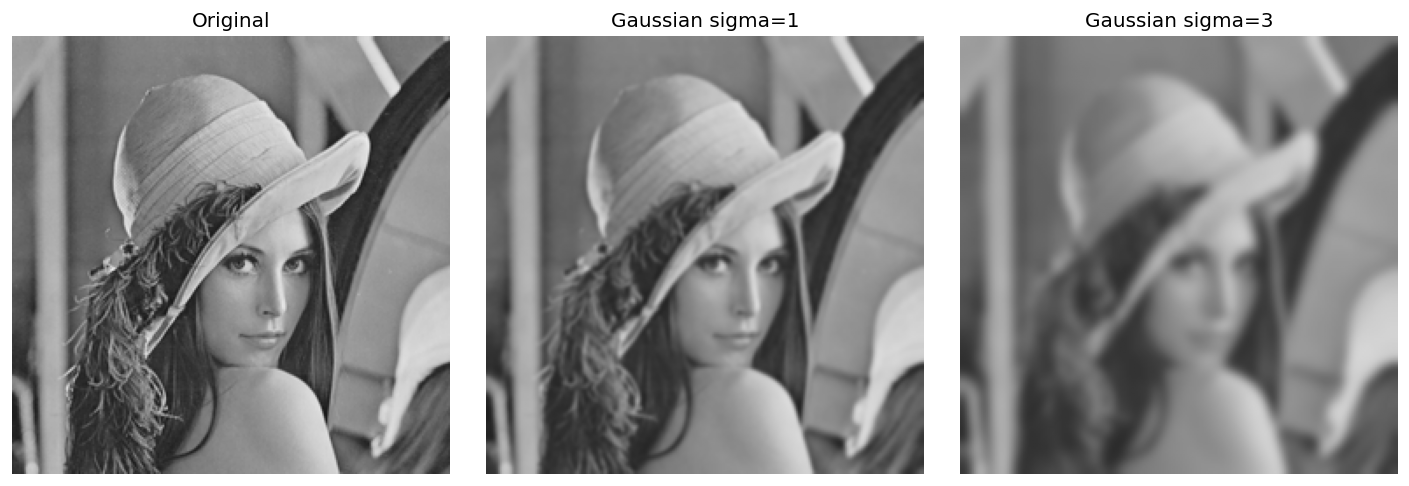

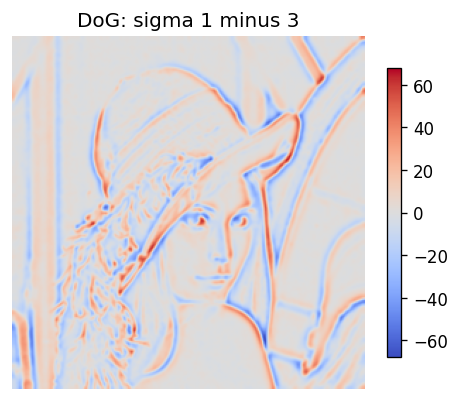

In [10]:
# 셀 10: 가우시안 차분 DoG
# 서로 다른 두 흐림 결과를 빼 중간 규모의 변화를 추출한다.

# DoG: 동일 크기 25x25 커널로 두 스케일을 비교합니다.
g1=cv2.GaussianBlur(f,(25,25),1.0,borderType=border)
g2=cv2.GaussianBlur(f,(25,25),3.0,borderType=border)
# 덜 흐린 결과에서 더 흐린 결과를 뺀다. 음수도 의미가 있으므로 절댓값을 취하지 않는다.
dog=g1-g2
panel('dog_blurs.png',[('Original',f),('Gaussian sigma=1',g1),('Gaussian sigma=3',g2)])
panel('dog_signed.png',[('DoG: sigma 1 minus 3',dog)],cols=1,signed=True)

constant=np.full_like(f,100)
dc=cv2.GaussianBlur(constant,(25,25),1)-cv2.GaussianBlur(constant,(25,25),3)
assert np.max(np.abs(dc))<1e-3
print('DoG 범위:',float(dog.min()),float(dog.max()))
print('일정한 영상의 최대 절대 응답:',float(np.abs(dc).max()))

### 공간 영역에서의 밴드패스 특성

정규화된 연속 가우시안 모델의 주파수 응답은 다음과 같다.

$$
H(\rho)=e^{-2\pi^2\sigma_1^2\rho^2}-e^{-2\pi^2\sigma_2^2\rho^2}
$$

$\rho$는 공간 주파수의 크기이며 단위는 cycles/pixel이다.



- $\rho=0$에서 응답은 0이므로 일정한 밝기 성분을 제거한다.
- 중간 주파수에서 반응하고 높은 주파수로 갈수록 줄어든다.
- 이상적인 직사각형 대역 통과가 아니라 부드러운 응답이다.
- 그림은 연속 모델이며 실제 25×25 이산 커널의 정확한 응답을 측정한 그래프는 아니다.
- 유한 커널·샘플링·경계 처리 때문에 실제 결과는 연속 모델과 차이가 있다.
- 공간에서 직접 계산해도 주파수 선택 특성을 설명할 수 있다. DFT 수행 자체가 필수는 아니다.

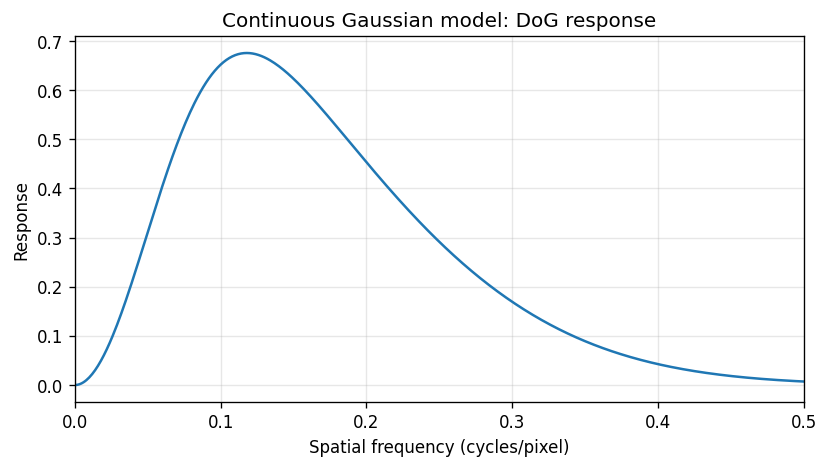

In [11]:
# 셀 11: DoG의 주파수 응답
# 연속 가우시안 모델의 응답을 그린다. 실제 유한 이산 커널의 측정값은 아니다.

nu=np.linspace(0,.5,501)
response=np.exp(-2*np.pi**2*1**2*nu**2)-np.exp(-2*np.pi**2*3**2*nu**2)
fig,ax=plt.subplots(figsize=(7,4)); ax.plot(nu,response)
ax.set(xlabel='Spatial frequency (cycles/pixel)',ylabel='Response',title='Continuous Gaussian model: DoG response',xlim=(0,.5))
ax.grid(alpha=.3); fig.tight_layout(); plt.show()

## 참고 문서

- [OpenCV Image Filtering API](https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html)
- [OpenCV Morphological Transformations](https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html)

## 실행 검증

OpenCV 5.0.0에서 11개 코드 셀을 같은 Python 실행 상태로 순차 실행하여 출력과 그림을 기록했다. 앞선 실행에서 확인한 Jupyter 커널 통신 권한 제한으로, 이번 검증은 Python 순차 실행으로 진행했다. Jupyter 전체 실행 자체는 검증하지 않았다.